In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#Carga de los datos y creación de la copia de seguridad del dataset
data = pd.read_csv("../Beats_PM/train.csv")
data_set_original = data.copy()

NameError: name 'pd' is not defined

In [4]:
#Verificación de datos falatantes y nulos
vacio = data.isna().sum()
nulo = data.isnull().sum()
print(f"La cantidad de líneas vacías por columna es: \n{vacio}")
print(f"\nLa cantidad de valores nulos es: \n{nulo}")

La cantidad de líneas vaciías por columna es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64

La cantidad de valores nulos es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64


In [5]:
#Verificación de filas duplicadas
print("          Filas Duplicadas")
display(data[data.duplicated(keep=False)])

          Filas Duplicadas


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


In [9]:
#Evaluación estadística del dataset
print("\nInformación del dataset:\n")
print(data.info())
print("\nDescripción estadística del dataset:\n")
print(data.describe())


Información del dataset:

<class 'pandas.DataFrame'>
RangeIndex: 524164 entries, 0 to 524163
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id                         524164 non-null  int64  
 1   RhythmScore                524164 non-null  float64
 2   AudioLoudness              524164 non-null  float64
 3   VocalContent               524164 non-null  float64
 4   AcousticQuality            524164 non-null  float64
 5   InstrumentalScore          524164 non-null  float64
 6   LivePerformanceLikelihood  524164 non-null  float64
 7   MoodScore                  524164 non-null  float64
 8   TrackDurationMs            524164 non-null  float64
 9   Energy                     524164 non-null  float64
 10  BeatsPerMinute             524164 non-null  float64
dtypes: float64(10), int64(1)
memory usage: 44.0 MB
None

Descripción estadística del dataset:

                  id    RhythmScore 

In [19]:
#Forma del dataset
filas, columnas = data.shape
print(f"\nForma del Dataset\nFilas: {filas}\nColumnas: {columnas}")


Forma del Dataset
Filas: 524164
Columnas: 11


In [40]:
# Condición: La energía, los beats por minuto y la duración de la canción no deben tener valores negativos.
#Así validamos que los datos no generen inconsistencias.
filtro_energy = (data["Energy"] < 0)
filtro_beat = (data["BeatsPerMinute"] < 0)
filtro_duracion = (data["TrackDurationMs"] <= 0)

print("Filas que contienen valores negativos de energía o de beats")
display(data[filtro_energy])
display(data[filtro_beat])
display(data[filtro_duracion])

Filas que contienen valores negativos de energía o de beats


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


In [ ]:
#Valorea atípicos

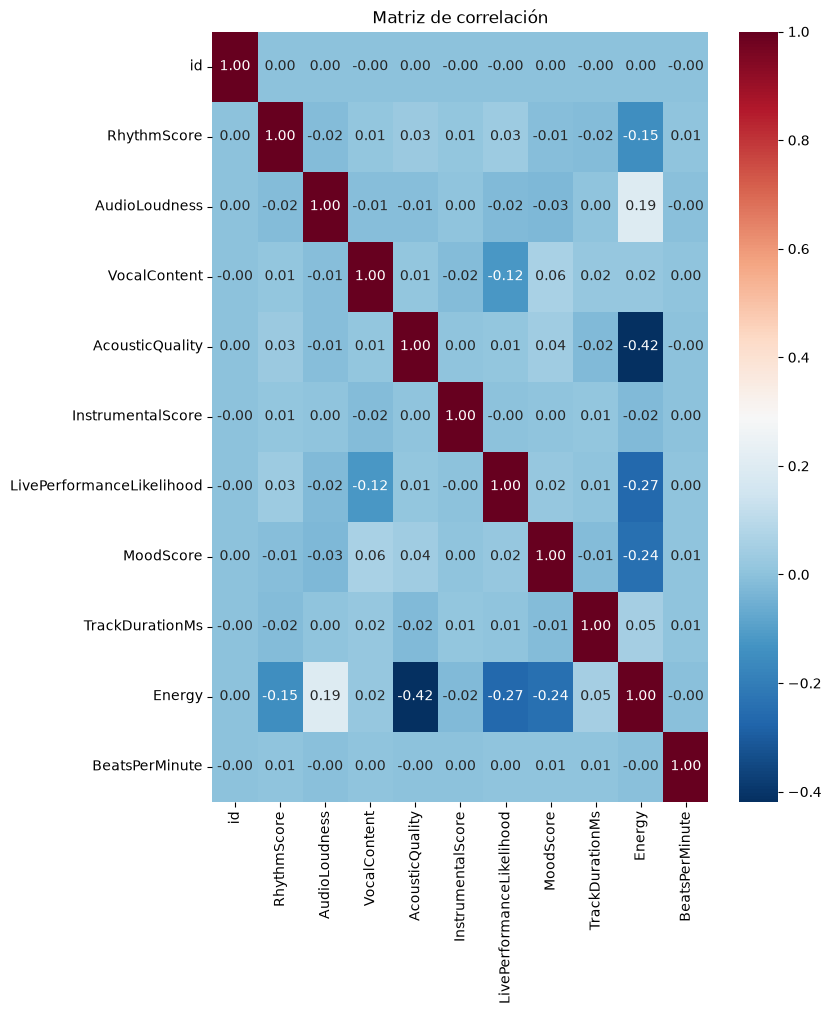

In [34]:
# Visualización de la correlación entre variables
plt.figure(figsize=(8, 10))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='RdBu_r')
plt.title('Matriz de correlación')
plt.show()

Con la evaluación de los datos se puede tener certeza de su uso, ya que, la validaciones y los rangos se ajustan a la necesidad.

Hay columnas que se evidencia que los valores están normalizados, estas columnas son: "AcousticQuality", "InstrumentalScore" y "Energy"

HAy columnas con valores que se pueden tomar como outliners pero, como los valores ya fueron tratados se pueden iniciar las pruebas para verificar el funcionamiento del algoritmo de entrenamiento.

a continuación la verificación de los datos del dataset de test que proporcionan.

In [41]:
#Carga de los datos y creación de la copia de seguridad del dataset
data_test = pd.read_csv("C:/Users/PcDroide/Documents/MasterUE_IA/Machine_Learning/Proyecto/Beats_PM/test.csv")
data_set_original = data_test.copy()

In [42]:
#Carga de los datos y creación de la copia de seguridad del dataset
data = pd.read_csv("C:/Users/PcDroide/Documents/MasterUE_IA/Machine_Learning/Proyecto/Beats_PM/train.csv")
data_set__test_original = data_test.copy()

In [43]:
#Verificación de datos falatantes y nulos
vacio = data_test.isna().sum()
nulo = data_test.isnull().sum()
print(f"La cantidad de líneas vacías por columna es: \n{vacio}")
print(f"\nLa cantidad de valores nulos es: \n{nulo}")

La cantidad de líneas vacías por columna es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64

La cantidad de valores nulos es: 
id                           0
RhythmScore                  0
AudioLoudness                0
VocalContent                 0
AcousticQuality              0
InstrumentalScore            0
LivePerformanceLikelihood    0
MoodScore                    0
TrackDurationMs              0
Energy                       0
BeatsPerMinute               0
dtype: int64


In [44]:
#Verificación de filas duplicadas
print("          Filas Duplicadas")
display(data_test[data_test.duplicated(keep=False)])

          Filas Duplicadas


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


In [45]:
#Evaluación estadística del dataset
print("\nInformación del dataset:\n")
print(data_test.info())
print("\nDescripción estadística del dataset:\n")
print(data_test.describe())


Información del dataset:

<class 'pandas.DataFrame'>
RangeIndex: 524164 entries, 0 to 524163
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   id                         524164 non-null  int64  
 1   RhythmScore                524164 non-null  float64
 2   AudioLoudness              524164 non-null  float64
 3   VocalContent               524164 non-null  float64
 4   AcousticQuality            524164 non-null  float64
 5   InstrumentalScore          524164 non-null  float64
 6   LivePerformanceLikelihood  524164 non-null  float64
 7   MoodScore                  524164 non-null  float64
 8   TrackDurationMs            524164 non-null  float64
 9   Energy                     524164 non-null  float64
 10  BeatsPerMinute             524164 non-null  float64
dtypes: float64(10), int64(1)
memory usage: 44.0 MB
None

Descripción estadística del dataset:

                  id    RhythmScore 

In [46]:
# Condición: La energía, los beats por minuto y la duración de la canción no deben tener valores negativos.
#Así validamos que los datos no generen inconsistencias.
filtro_energy = (data_test["Energy"] < 0)
filtro_beat = (data_test["BeatsPerMinute"] < 0)
filtro_duracion = (data_test["TrackDurationMs"] <= 0)

print("Filas que contienen valores negativos de energía o de beats")
display(data_test[filtro_energy])
display(data_test[filtro_beat])
display(data_test[filtro_duracion])

Filas que contienen valores negativos de energía o de beats


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


,id,RhythmScore,AudioLoudness,VocalContent,AcousticQuality,InstrumentalScore,LivePerformanceLikelihood,MoodScore,TrackDurationMs,Energy,BeatsPerMinute


Al realizar las mismas validaciones de los datos que se realizaron en el conjunto de entrenamiento, se obtuvieron los mismos resultado, por esta razón el conjuto de datos de test también estaría listo para partirlo y utilizar una parte en ajustes del algoritmo y la otra en la verificación final del modelo.